In [1]:
import pandas as pd
import numpy as np
import torch 
import matplotlib.pyplot as plt

# GPLVM for missing data in developability assays 

Data from this paper: https://www.pnas.org/doi/10.1073/pnas.2026658118

10 versions of 3 assays to do with how well a protein can be produced (6 of assay 1, 2 of assay 2, and 2 of assay 3)

can also include IQ and SH which are the high fidelity, more expensive bacterial assays but have some missing data


In [2]:
np.random.seed(2026)

In [3]:
# data = pd.read_excel('/Users/rsedgwick/Downloads/pnas.1616408114.sd03.xlsx')
# data = data.iloc[:137]
# get all columns except 'Name'
# data_np = data.drop(columns=['Name']).to_numpy()

data = pd.read_csv('assay_to_yield_training_sequences.csv')
# data_np = data.drop(columns=['Unnamed: 0', '#OTU ID', 'DNA', 'Paratope', 'Stop', 'CC', 'Position_x', 'Position_y', 'One_Hot', 'Ordinal']).to_numpy()

# get only the assay score columns as numpy array
data_np = data[['Sort1_mean_score', 
       'Sort2_mean_score',
       'Sort3_mean_score',
       'Sort4_mean_score',
       'Sort5_mean_score', 
       'Sort6_mean_score',
       'Sort7_mean_score', 
       'Sort8_mean_score',
       'Sort9_mean_score', 
       'Sort10_mean_score',
]].to_numpy() 
#       'IQ_Average',
      # 'SH_Average'

# cast data_np to float type 
data_np = data_np.astype(float)

In [4]:
data.head()

,Unnamed: 0,#OTU ID,DNA,Paratope,Stop,CC,Sort1_1_score,Sort1_2_score,Sort1_3_score,Sort2_1_score,...,IQ_Average_bc,IQ_Trial1_Adj_bc,IQ_Trial2_Adj_bc,IQ_Trial3_Adj_bc,IQ_Average_bc_std,SH_Average_bc,SH_Trial1_Adj_bc,SH_Trial2_Adj_bc,SH_Trial3_Adj_bc,SH_Average_bc_std
0,982,Zotu1433,AAATTTTGGGCGACTGTAGGTGTGTATCGTTTGTCGAGGCATTTTG...,GVYRLSRHPKLXXALQ,False,0,0.219029,0.488903,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,-0.041369,-0.137243,0.460557,-1.012433,0.740836
1,1008,Zotu1480,AAATTTTGGGCGACTGTATGTCCGAGTCATCATGGTCGTTGTTTTG...,CPSHHGRCLRFRREHG,False,1,0.491984,0.842559,0.921503,0.614348,...,NaN,NaN,NaN,NaN,NaN,1.250529,1.118242,1.054481,1.476938,0.227742
2,1196,Zotu1826,AAATTTTGGGCGACTGTATGTCATCTTTCGGTGTGTTTTGAGGTGC...,CHLXXSVCLVLRDVNG,False,1,0.666667,0.333333,0.887965,0.331793,...,NaN,NaN,NaN,NaN,NaN,0.641699,1.243834,-1.361552,0.320088,1.320938
3,1217,Zotu1862,AAATTTTGGGCGACTGTATGTGGTCGTGATCGTTGGTGTTTTGAGG...,CGRDXRWCHVFXXLCG,False,1,0.974636,0.974391,1.000000,0.874199,...,-0.00654,0.220159,-0.503406,0.105802,0.388964,0.668209,0.295409,1.186681,-0.183638,0.695416
4,1316,Zotu2013,AAATTTTGGGCGACTGTATGTATGGGTTCTCCGTGGTGTTTTGAGG...,CMGSXPWCVGQXXSCT,False,1,0.930717,0.993982,1.000000,0.659117,...,-0.18297,-0.550264,-0.188980,0.081603,0.317017,1.256685,1.558167,1.416891,-0.463381,1.128572


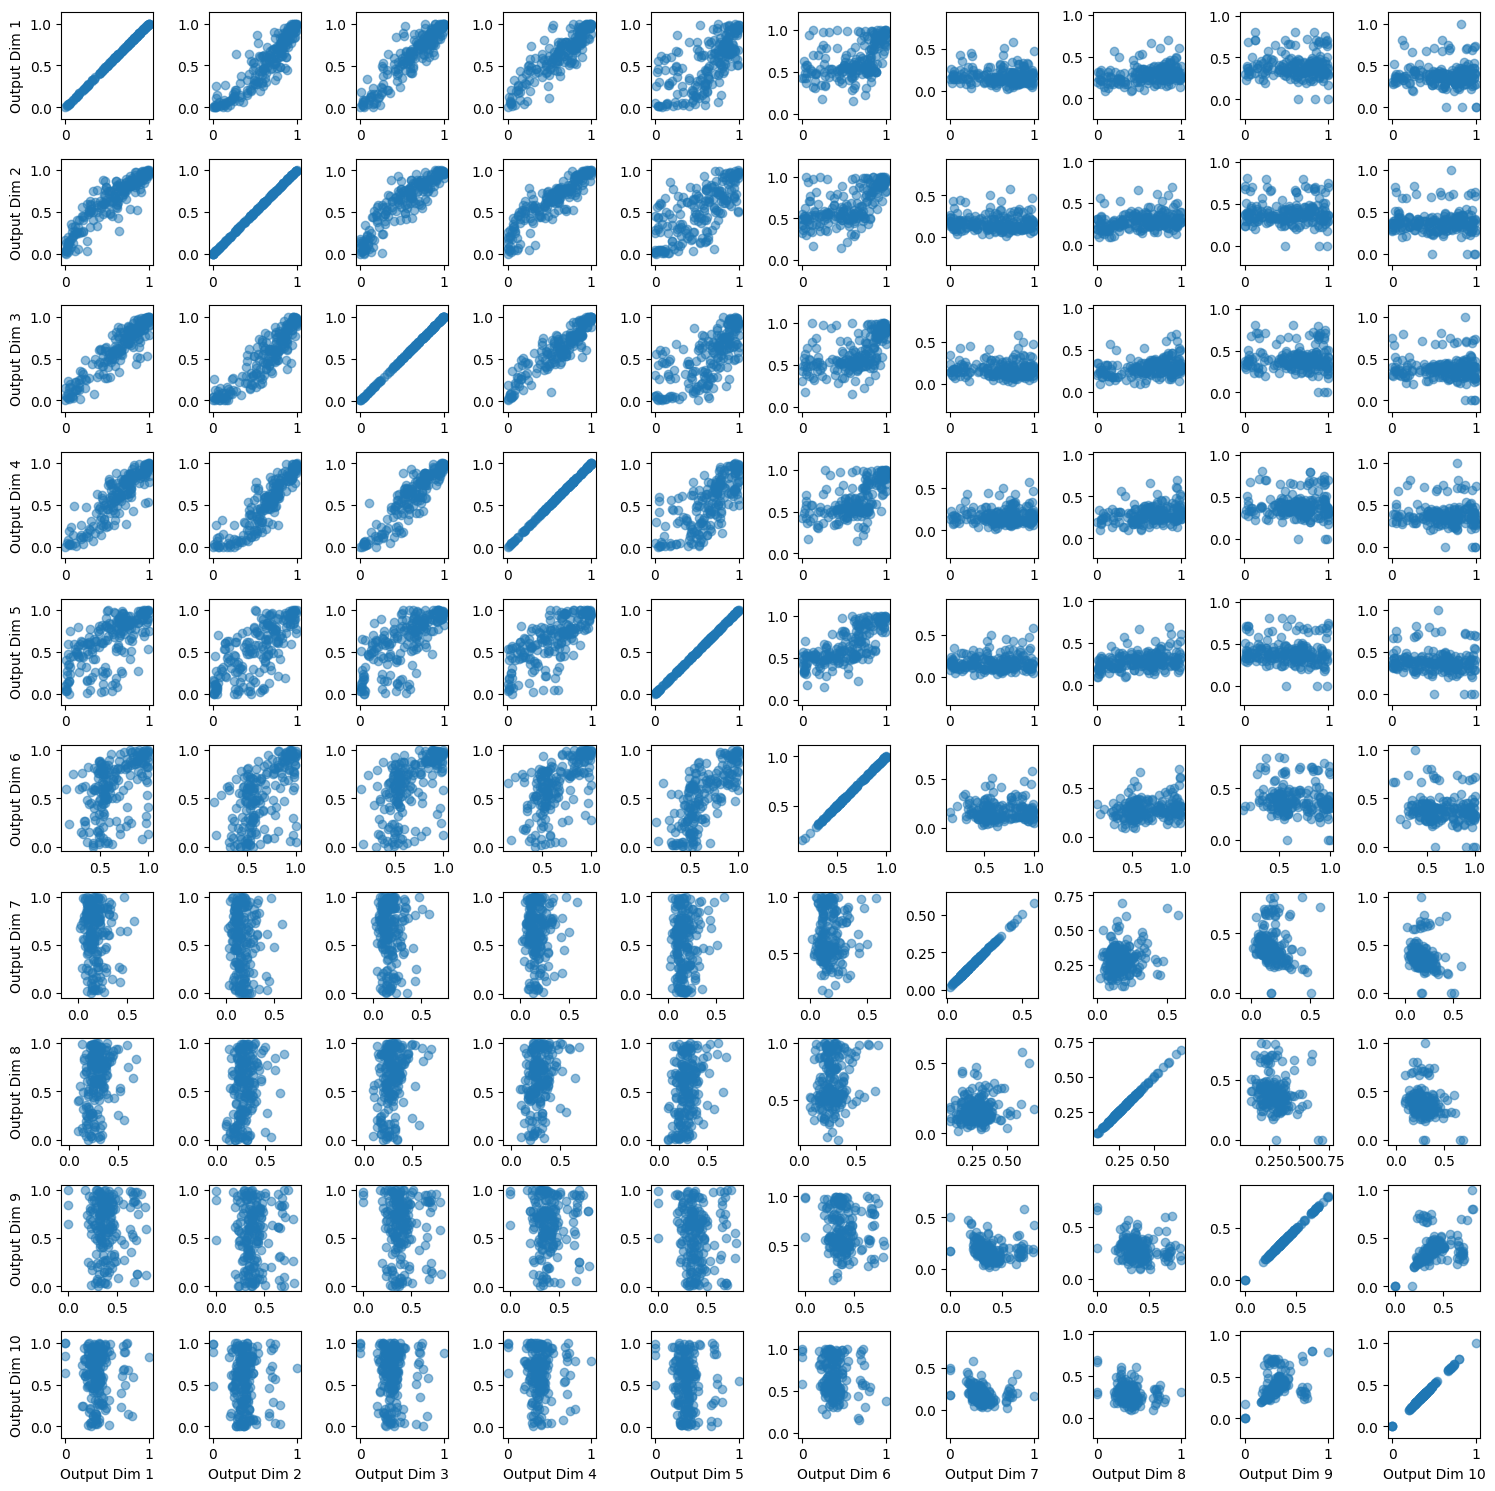

In [5]:
# plot the columns against each other in a scatter matrix

fig, axs = plt.subplots(nrows=len(data_np[0]), ncols=len(data_np[0]), figsize=(15, 15))
for i in range(len(data_np[0])):
    for j in range(len(data_np[0])):
        axs[i, j].scatter(data_np[:, i], data_np[:, j], alpha=0.5)
        axs[i, j].axis('equal')
        axs[i, 0].set_ylabel(f'Output Dim {i+1}')
        axs[-1, j].set_xlabel(f'Output Dim {j+1}')

plt.tight_layout()
plt.show()


In [6]:
# Create a mask and introduce missing values to data_np
missing_rate = 0.15  # 15% missing values

# Create a random mask (True = missing, False = observed)
missing_mask = np.random.rand(*data_np.shape) < missing_rate

# Create a copy of data_np with NaN values
data_np_with_missing = data_np.copy()
data_np_with_missing[missing_mask] = np.nan

print(f"Total values: {data_np.size}")
print(f"Missing values: {missing_mask.sum()}")
print(f"Missing percentage: {100 * missing_mask.sum() / data_np.size:.2f}%")
print(f"Data shape: {data_np_with_missing.shape}")


Total values: 1950
Missing values: 285
Missing percentage: 14.62%
Data shape: (195, 10)


In [7]:
# Prepare data
observed_data = torch.tensor(data_np_with_missing, dtype=torch.float64)
mask = ~torch.isnan(observed_data)
observed_data[~mask] = 0.0

# Normalize
data_mean = observed_data.sum(0) / mask.sum(0)
data_std = ((observed_data - data_mean)**2 * mask).sum(0).sqrt() / mask.sum(0).sqrt()
data_norm = (observed_data - data_mean) / (data_std + 1e-6)
data_norm[~mask] = 0.0

In [8]:
# Fit a Bayesian GPLVM to the data with missing values
from gpytorch.models.gplvm.latent_variable import VariationalLatentVariable
from gpytorch.models.gplvm.bayesian_gplvm import BayesianGPLVM
from gpytorch.means import ZeroMean
from gpytorch.kernels import RBFKernel, ScaleKernel
from gpytorch.variational import VariationalStrategy, CholeskyVariationalDistribution
from gpytorch.distributions import MultivariateNormal
from gpytorch.likelihoods import GaussianLikelihood
from gpytorch.mlls.variational_elbo import VariationalELBO
from gpytorch.priors import NormalPrior


class BayesianGPLVMModel(BayesianGPLVM):
    def __init__(self, n, data_dim, latent_dim, n_inducing):
        self.n = n
        self.batch_shape = torch.Size([data_dim])
        
        # Inducing points
        self.inducing_inputs = torch.randn(data_dim, n_inducing, latent_dim, dtype=torch.float64)
        
        # Variational distribution
        q_u = CholeskyVariationalDistribution(n_inducing, batch_shape=self.batch_shape)
        q_f = VariationalStrategy(self, self.inducing_inputs, q_u, learn_inducing_locations=True)
        
        # Latent variable with prior
        X_prior_mean = torch.zeros(n, latent_dim, dtype=torch.float64)
        prior_x = NormalPrior(X_prior_mean, torch.ones_like(X_prior_mean))
        X_init = torch.nn.Parameter(torch.randn(n, latent_dim, dtype=torch.float64) * 0.1)
        X = VariationalLatentVariable(n, data_dim, latent_dim, X_init, prior_x)
        
        super().__init__(X, q_f)
        
        # Mean and kernel - kernel shared across all output dimensions
        self.mean_module = ZeroMean(batch_shape=self.batch_shape)
        self.covar_module = ScaleKernel(
            RBFKernel(ard_num_dims=latent_dim),  # No batch_shape - shared across outputs
            batch_shape=self.batch_shape  # Only scale kernel is batched
        )

    def forward(self, X):
        mean_x = self.mean_module(X)
        covar_x = self.covar_module(X)
        return MultivariateNormal(mean_x, covar_x)

latent_dim = 5
num_data, data_dim = observed_data.shape
n_inducing = 20

model = BayesianGPLVMModel(num_data, data_dim, latent_dim, n_inducing)
likelihood = GaussianLikelihood(batch_shape=model.batch_shape)
mll = VariationalELBO(likelihood, model, num_data)
optimizer = torch.optim.Adam(list(model.parameters()) + list(likelihood.parameters()), lr=0.01)

num_iterations = 2000
model.to(torch.float64)
model.train()
likelihood.train()

for i in range(num_iterations):
    optimizer.zero_grad()
    sample = model.sample_latent_variable()
    output = model(sample)
    
    # Compute loss - the ELBO returns shape [data_dim]
    # We sum across dimensions and negate for gradient descent
    loss = -mll(output, data_norm.t()).sum()
    
    loss.backward()
    optimizer.step()
    
    if i % 100 == 0:
        print(f'Iteration {i}/{num_iterations} - Loss: {loss.item():.4f}')

# Predict
model.eval()
likelihood.eval()
with torch.no_grad():
    X_latent = model.X.q_mu
    output = model(X_latent)
    predictions = torch.stack([likelihood(output[j]).mean for j in range(data_dim)], dim=1)
    predictions = predictions * (data_std + 1e-6) + data_mean
    
    # Fill in missing values
    completed_data = observed_data.clone()
    completed_data[~mask] = predictions[~mask]

print(completed_data)

Iteration 0/2000 - Loss: 20.5117
Iteration 100/2000 - Loss: 14.9889
Iteration 200/2000 - Loss: 13.8539
Iteration 300/2000 - Loss: 13.1458
Iteration 400/2000 - Loss: 12.5262
Iteration 500/2000 - Loss: 12.3611
Iteration 600/2000 - Loss: 12.1444
Iteration 700/2000 - Loss: 12.0901
Iteration 800/2000 - Loss: 12.0637
Iteration 900/2000 - Loss: 12.0602
Iteration 1000/2000 - Loss: 12.0820
Iteration 1100/2000 - Loss: 11.8714
Iteration 1200/2000 - Loss: 11.8769
Iteration 1300/2000 - Loss: 11.8495
Iteration 1400/2000 - Loss: 11.7600
Iteration 1500/2000 - Loss: 11.9740
Iteration 1600/2000 - Loss: 11.8904
Iteration 1700/2000 - Loss: 11.9028
Iteration 1800/2000 - Loss: 11.8521
Iteration 1900/2000 - Loss: 11.9288
tensor([[0.2360, 0.1239, 0.0284,  ..., 0.2378, 0.3298, 0.6658],
        [0.7520, 0.6994, 0.6382,  ..., 0.3136, 0.3344, 0.2923],
        [0.5181, 0.3782, 0.4753,  ..., 0.2776, 0.3311, 0.3350],
        ...,
        [0.7801, 0.7089, 0.8537,  ..., 0.1556, 0.4024, 0.4411],
        [0.8579, 0.7234

In [9]:
for name, param in model.named_parameters():
    print(f"{name}: {param.size()}")

variational_strategy.inducing_points: torch.Size([10, 20, 5])
variational_strategy._variational_distribution.variational_mean: torch.Size([10, 20])
variational_strategy._variational_distribution.chol_variational_covar: torch.Size([10, 20, 20])
X.q_mu: torch.Size([195, 5])
X.q_log_sigma: torch.Size([195, 5])
covar_module.raw_outputscale: torch.Size([10])
covar_module.base_kernel.raw_lengthscale: torch.Size([1, 5])


/var/folders/kx/7zm2zp_54d14zbwnnl84lxlc0000gp/T/ipykernel_62198/3190979116.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')


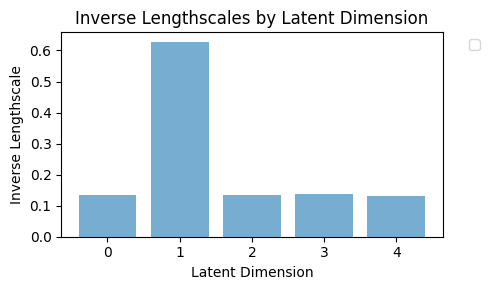

In [10]:
# plot the inverse lengthscales
import matplotlib.pyplot as plt

lengthscales = model.covar_module.base_kernel.lengthscale.detach().cpu().numpy()
inverse_lengthscales = 1.0 / lengthscales

plt.figure(figsize=(5, 3))

plt.bar(range(latent_dim), inverse_lengthscales[0], alpha=0.6)

plt.xlabel('Latent Dimension')
plt.ylabel('Inverse Lengthscale')
plt.title('Inverse Lengthscales by Latent Dimension')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

##  Plot the Latent Space

The latent points are coloured by whether the protein has a stabilising cyteine pair or not (CC+ for if protein is expected to have pair, CC- for if not)

CC+ should have better developability scores

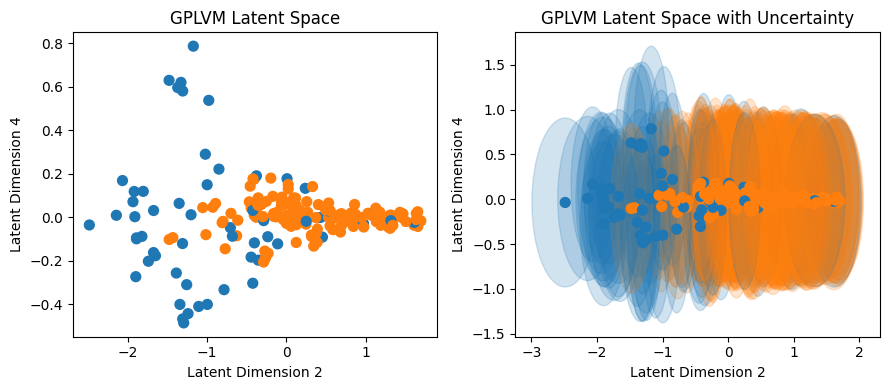

In [11]:
# plot latent variables 
from matplotlib.patches import Ellipse

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(9, 4))


# Extract the latent means
X_latent = model.X.q_mu.detach().cpu().numpy()

# colour by the stop column
stops = data['CC'].to_numpy()
unique_stops = np.unique(stops)
stop_colors = {stop: plt.cm.tab10(i) for i, stop in enumerate(unique_stops)}
colors = [stop_colors[stop] for stop in stops]


# get the index of the two lengthscales with smallest values
lengthscales = model.covar_module.base_kernel.lengthscale.detach().cpu().numpy()
sorted_indices = np.argsort(lengthscales[0])
dim1, dim2 = sorted_indices[:2]


axs[0].scatter(X_latent[:, dim1], X_latent[:, dim2], c=colors, s=50)
axs[0].set_xlabel(f'Latent Dimension {dim1 + 1}')
axs[0].set_ylabel(f'Latent Dimension {dim2 + 1}')
axs[0].set_title('GPLVM Latent Space')


# use elipses to show uncertainty
X_std = torch.nn.functional.softplus(model.X.q_log_sigma).detach().cpu().numpy()
for i in range(X_latent.shape[0]):
    ellipse = Ellipse(xy=(X_latent[i, dim1], X_latent[i, dim2]),
                      width=2 * X_std[i, dim1],
                      height=2 * X_std[i, dim2],
                      angle=0,
                      alpha=0.2,
                      color=colors[i])
    axs[1].add_patch(ellipse)
axs[1].scatter(X_latent[:, dim1], X_latent[:, dim2], c=colors, s=50)
axs[1].set_xlabel(f'Latent Dimension {dim1 + 1}')
axs[1].set_ylabel(f'Latent Dimension {dim2 + 1}')
axs[1].set_title('GPLVM Latent Space with Uncertainty')

plt.tight_layout()

In [12]:
# Predict outputs for the unobserved data and compare NLPD and RMSE
model.eval()
likelihood.eval()

with torch.no_grad():
    X_latent = model.X.q_mu
    output = model(X_latent)
    
    # Get predictive mean and variance for each output dimension
    pred_means = []
    pred_vars = []
    for j in range(data_dim):
        pred_dist = likelihood(output[j])
        pred_means.append(pred_dist.mean)  # Shape: [137]
        # Extract diagonal variance only (ignore batch covariance)
        var = pred_dist.variance  # Shape: [12, 137] (batch, data)
        pred_vars.append(var[j])  # Extract the j-th dimension's variance [137]
    
    # Stack: each element is [137], so stack along dim=1 to get [137, 12]
    pred_means = torch.stack(pred_means, dim=1)
    pred_vars = torch.stack(pred_vars, dim=1)
    
    # # Unnormalize predictions
    # pred_means = pred_means * (data_std + 1e-6) + data_mean
    # pred_vars = pred_vars * ((data_std + 1e-6)**2)

# get the normalised data 
all_data = torch.tensor(data_np, dtype=torch.float64)
data_norm_all = (all_data - data_mean) / (data_std + 1e-6)

# calculate the nlpd and rmse of the model and the mean predictions for the standardised data

#mask by only the missing values    
missing_mask_tensor = ~mask

rmse_per_datum = torch.sqrt(((pred_means - data_norm_all)**2))
rmse_per_datum_masked = rmse_per_datum.clone()
rmse_per_datum_masked[mask] = float('nan')
rmse_norm_by_dim = rmse_per_datum_masked.nanmean(dim=0)


nlpd_per_datum = 0.5 * torch.log(2 * np.pi * pred_vars) + \
           0.5 * ((data_norm_all - pred_means)**2) / pred_vars
nlpd_per_datum_masked = nlpd_per_datum.clone()
nlpd_per_datum_masked[mask] = float('nan')
nlpd_norm_by_dim = nlpd_per_datum_masked.nanmean(dim=0)

print('--- model results ---')

# print(f'rmse_norm_by_dim: {rmse_norm_by_dim}')
# print(f'nlpd_norm_by_dim: {nlpd_norm_by_dim}')
print(f'total rmse: {rmse_norm_by_dim.mean().item()}')
print(f'total nlpd: {nlpd_norm_by_dim.mean().item()}')

data_norm_mean = data_norm.mean(0).unsqueeze(0).expand_as(data_norm)
data_norm_std = data_norm.std(0).unsqueeze(0).expand_as(data_norm)
rmse_per_datum_mean = torch.sqrt(((data_norm_mean - data_norm_all)**2))
rmse_per_datum_mean_masked = rmse_per_datum_mean.clone()
rmse_per_datum_mean_masked[mask] = float('nan')
rmse_norm_by_dim_mean = rmse_per_datum_mean_masked.nanmean(dim=0)
nlpd_per_datum_mean = 0.5 * torch.log(2 * np.pi * (data_norm_std**2)) + \
           0.5 * ((data_norm_all - data_norm_mean)**2) / (data_norm_std**2)
nlpd_per_datum_mean_masked = nlpd_per_datum_mean.clone()
nlpd_per_datum_mean_masked[mask] = float('nan')
nlpd_norm_by_dim_mean = nlpd_per_datum_mean_masked.nanmean(dim=0)
print('--- mean predictor results ---')
# print(f'mean rmse_norm_by_dim: {rmse_norm_by_dim_mean}')
# print(f'mean nlpd_norm_by_dim: {nlpd_norm_by_dim_mean}')
print(f'mean total rmse: {rmse_norm_by_dim_mean.mean().item()}')
print(f'mean total nlpd: {nlpd_norm_by_dim_mean.mean().item()}')


results_df = pd.DataFrame({
    'Output Dimension': [f'Dim {i+1}' for i in range(data_dim)],
    'GPLVM RMSE': rmse_norm_by_dim.numpy(),
    'Mean Predictor RMSE': rmse_norm_by_dim_mean.numpy(),
    'GPLVM NLPD': nlpd_norm_by_dim.numpy(),
    'Mean Predictor NLPD': nlpd_norm_by_dim_mean.numpy()
})
print(results_df.to_string())

--- model results ---
total rmse: 0.5438709067640161
total nlpd: 1.038505161917231
--- mean predictor results ---
mean total rmse: 0.7853523899005949
mean total nlpd: 1.408914541096425
  Output Dimension  GPLVM RMSE  Mean Predictor RMSE  GPLVM NLPD  Mean Predictor NLPD
0            Dim 1    0.372508             0.894290    0.646099             1.573073
1            Dim 2    0.354596             0.855808    0.556121             1.385148
2            Dim 3    0.486983             0.953992    1.060403             1.636554
3            Dim 4    0.321805             0.690089    0.518078             1.297130
4            Dim 5    0.648710             0.959201    1.167582             1.539047
5            Dim 6    0.526516             0.756765    1.039848             1.289862
6            Dim 7    0.609462             0.607842    1.178215             1.170737
7            Dim 8    0.661761             0.686391    1.339994             1.334763
8            Dim 9    0.798700             0.79161

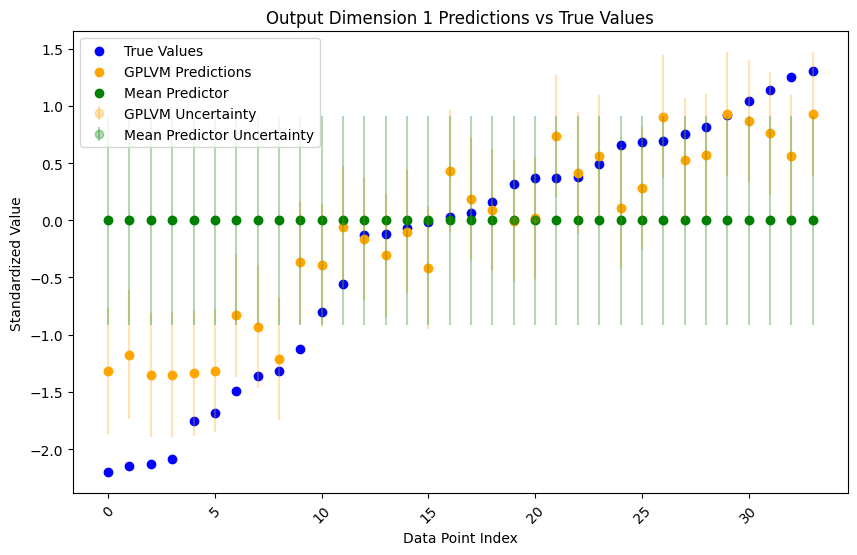

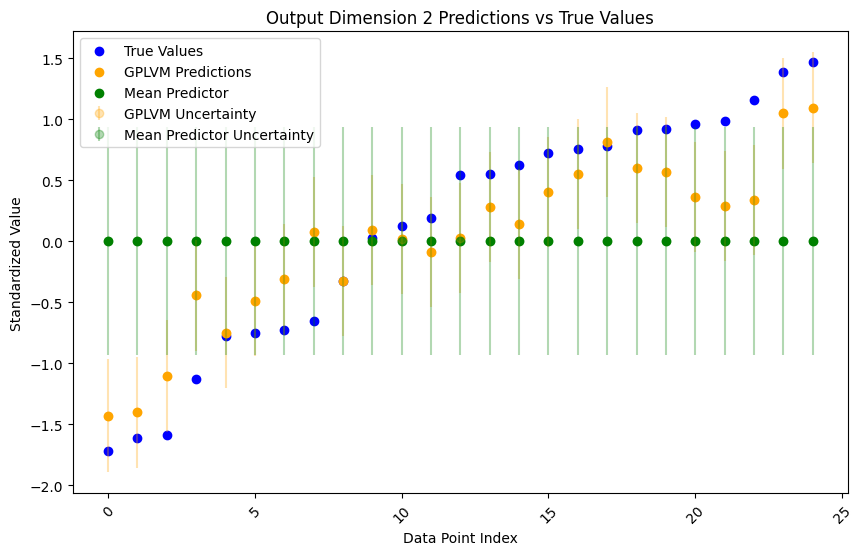

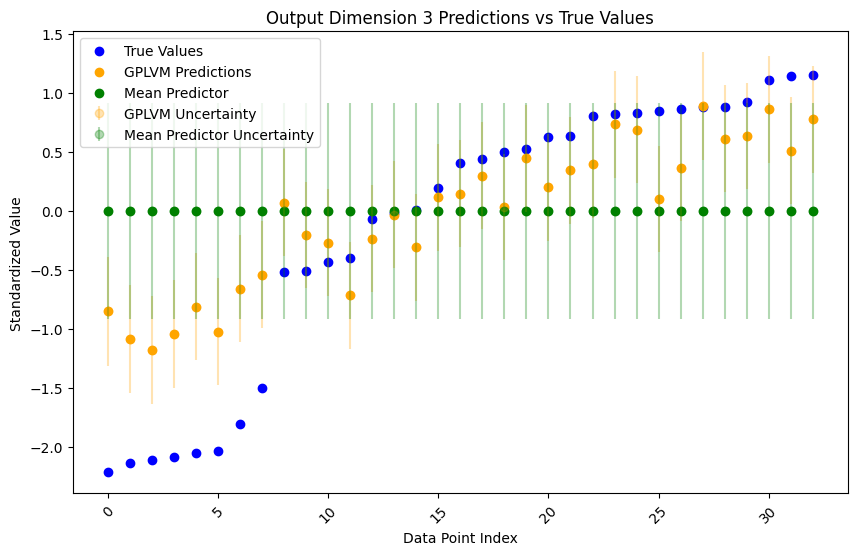

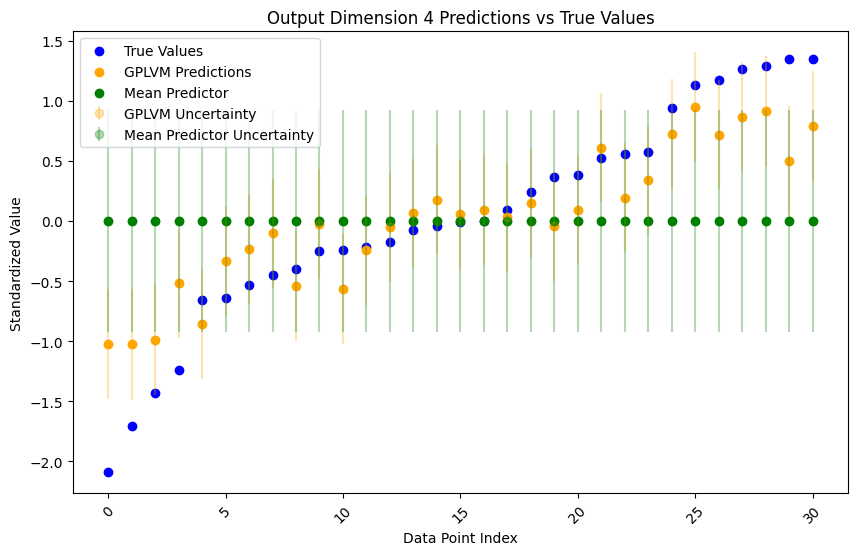

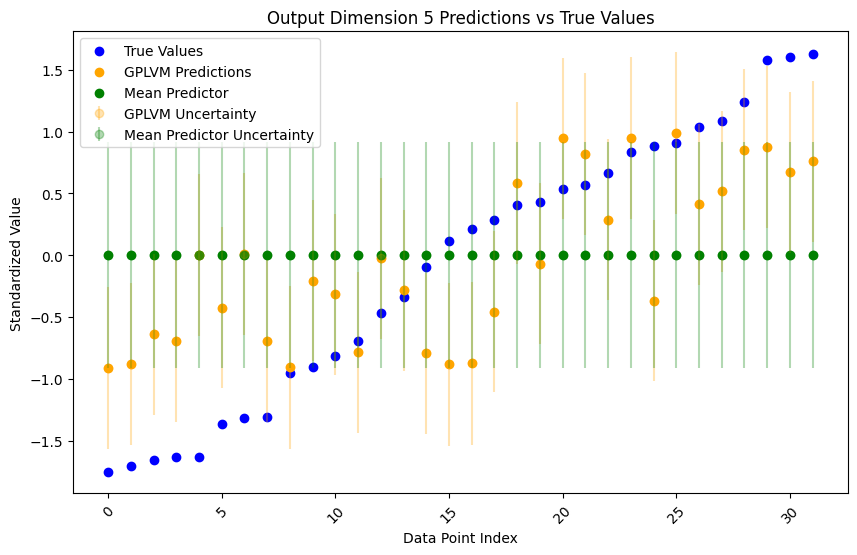

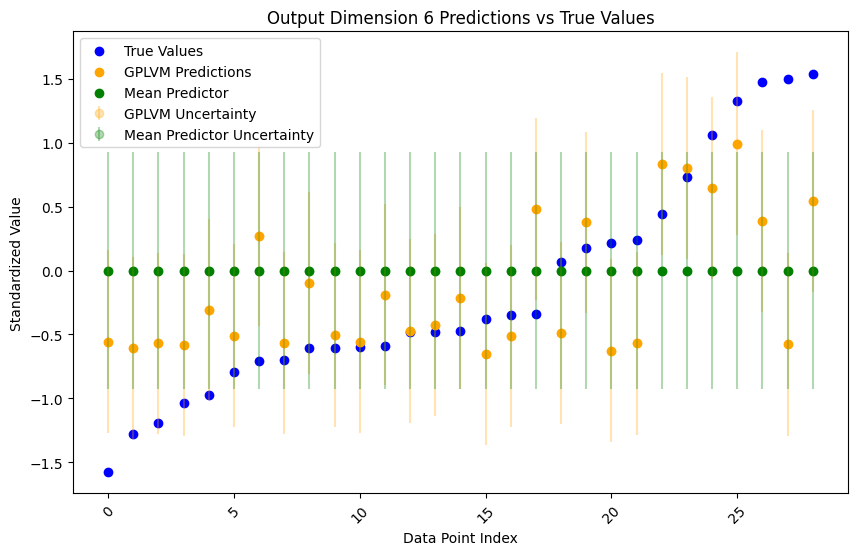

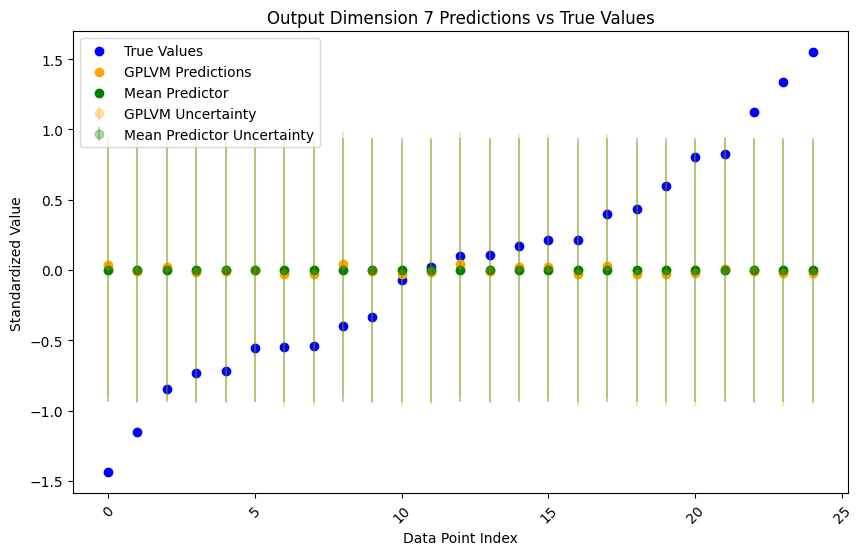

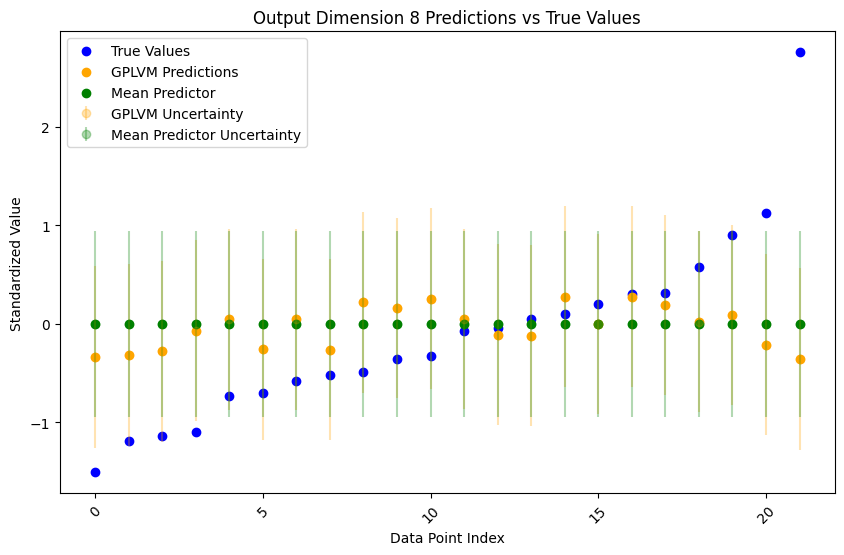

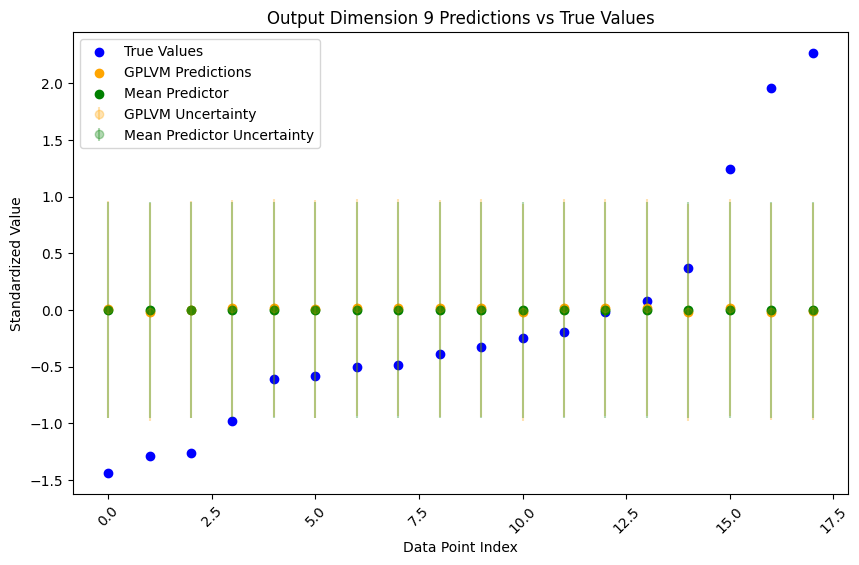

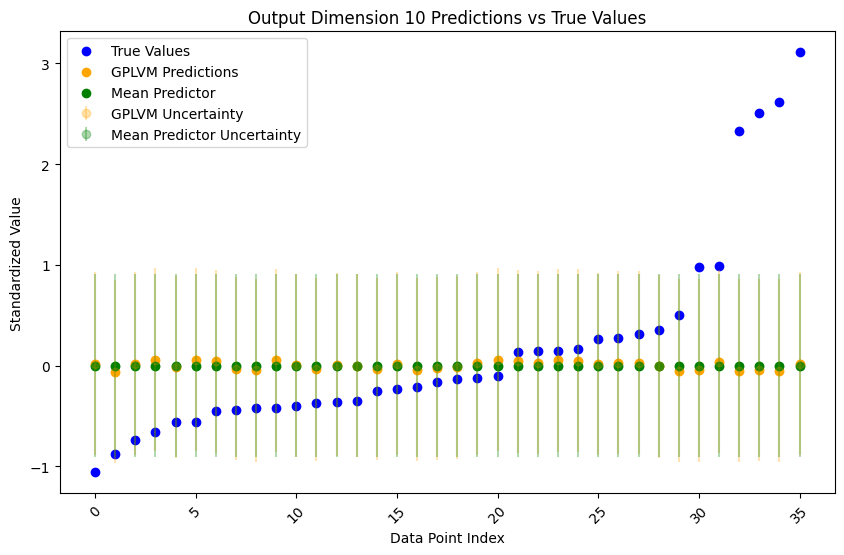

In [13]:
# plot these results

import matplotlib.pyplot as plt

true_missing_masked = data_norm_all.clone()
true_missing_masked[mask] = float('nan')

pred_means_masked = pred_means.clone()
pred_means_masked[mask] = float('nan')

pred_vars_masked = pred_vars.clone()
pred_vars_masked[mask] = float('nan')

data_norm_mean_masked = data_norm_mean.clone()
data_norm_mean_masked[mask] = float('nan')

data_norm_std_masked = data_norm_std.clone()
data_norm_std_masked[mask] = float('nan')

for j in range(data_dim):
    plt.figure(figsize=(10, 6))
    plt.title(f'Output Dimension {j+1} Predictions vs True Values')
    plt.xlabel('Data Point Index')
    plt.ylabel('Standardized Value')

    # Sort by true values for better visualization
    valid_indices = ~torch.isnan(true_missing_masked[:, j])
    true_sorted, sorted_indices = torch.sort(true_missing_masked[valid_indices, j])
    pred_sorted = pred_means_masked[valid_indices, j][sorted_indices]
    pred_std_sorted = torch.sqrt(pred_vars_masked[valid_indices, j][sorted_indices])
    mean_sorted = data_norm_mean_masked[valid_indices, j][sorted_indices]
    std_sorted = data_norm_std_masked[valid_indices, j][sorted_indices]
    
    plt.scatter(np.arange(len(true_sorted)), true_sorted.numpy(), label='True Values', color='blue')
    plt.scatter(np.arange(len(pred_sorted)), pred_sorted.numpy(), label='GPLVM Predictions', color='orange')
    plt.errorbar(np.arange(len(pred_sorted)), pred_sorted.numpy(), yerr=pred_std_sorted.numpy(), fmt='o', color='orange', alpha=0.3, label='GPLVM Uncertainty', linestyle='None')
   
    plt.scatter(np.arange(len(mean_sorted)), mean_sorted.numpy(), label='Mean Predictor', color='green')
    plt.errorbar(np.arange(len(mean_sorted)), mean_sorted.numpy(), yerr=std_sorted.numpy(), fmt='o', color='green', alpha=0.3, label='Mean Predictor Uncertainty', linestyle='None')
   
    
    plt.legend()
    plt.xticks(rotation=45)

# ------- IGNORE EVERYTHING BELOW THIS --------

In [14]:
# Predict outputs for the unobserved data and compare NLPD and RMSE
model.eval()
likelihood.eval()

with torch.no_grad():
    X_latent = model.X.q_mu
    output = model(X_latent)
    
    # Get predictive mean and variance for each output dimension
    pred_means = []
    pred_vars = []
    for j in range(data_dim):
        pred_dist = likelihood(output[j])
        pred_means.append(pred_dist.mean)  # Shape: [137]
        # Extract diagonal variance only (ignore batch covariance)
        var = pred_dist.variance  # Shape: [12, 137] (batch, data)
        pred_vars.append(var[j])  # Extract the j-th dimension's variance [137]
    
    # Stack: each element is [137], so stack along dim=1 to get [137, 12]
    pred_means = torch.stack(pred_means, dim=1)
    pred_vars = torch.stack(pred_vars, dim=1)
    
    # Unnormalize predictions
    pred_means = pred_means * (data_std + 1e-6) + data_mean
    pred_vars = pred_vars * ((data_std + 1e-6)**2)

    
    # Calculate metrics only on missing values
    missing_mask_tensor = ~mask
    
    # RMSE on missing values
    rmse = torch.sqrt(((pred_means[missing_mask_tensor] - observed_data[missing_mask_tensor])**2).mean())
    # print(pred_means[missing_mask_tensor])
    # NLPD (Negative Log Predictive Density) on missing values
    pred_std = torch.sqrt(pred_vars[missing_mask_tensor])
    nlpd = 0.5 * torch.log(2 * np.pi * pred_vars[missing_mask_tensor]) + \
           0.5 * ((observed_data[missing_mask_tensor] - pred_means[missing_mask_tensor])**2) / pred_vars[missing_mask_tensor]
    nlpd = nlpd.mean()
    
    print(f"RMSE on missing values: {rmse.item():.4f}")
    print(f"NLPD on missing values: {nlpd.item():.4f}")
    print(f"\nNumber of missing values: {missing_mask_tensor.sum().item()}")
    print(f"Total values: {observed_data.numel()}")

    # print the RMSE and NLPD for each output dimension
    results_dir = {}
    for j in range(data_dim):
        dim_missing_mask = missing_mask_tensor[:, j]
        dim_rmse = torch.sqrt(((pred_means[dim_missing_mask, j] - observed_data[dim_missing_mask, j])**2).mean())
        dim_pred_std = torch.sqrt(pred_vars[dim_missing_mask, j])
        dim_nlpd = 0.5 * torch.log(2 * np.pi * pred_vars[dim_missing_mask, j]) + \
                   0.5 * ((observed_data[dim_missing_mask, j] - pred_means[dim_missing_mask, j])**2) / pred_vars[dim_missing_mask, j]
        dim_nlpd = dim_nlpd.mean()
        print(f"Output Dimension {j+1} - RMSE: {dim_rmse.item():.4f}, NLPD: {dim_nlpd.item():.4f}")
        results_dir[f"{j+1}"] = {'RMSE': dim_rmse.item(), 'NLPD': dim_nlpd.item()}


RMSE on missing values: 0.5350
NLPD on missing values: 6.6077

Number of missing values: 285
Total values: 1950
Output Dimension 1 - RMSE: 0.6382, NLPD: 8.2616
Output Dimension 2 - RMSE: 0.5717, NLPD: 7.4270
Output Dimension 3 - RMSE: 0.6525, NLPD: 11.7424
Output Dimension 4 - RMSE: 0.6608, NLPD: 13.4199
Output Dimension 5 - RMSE: 0.5485, NLPD: 3.5286
Output Dimension 6 - RMSE: 0.6352, NLPD: 7.8568
Output Dimension 7 - RMSE: 0.1707, NLPD: 0.3737
Output Dimension 8 - RMSE: 0.2872, NLPD: 3.4108
Output Dimension 9 - RMSE: 0.4009, NLPD: 3.3538
Output Dimension 10 - RMSE: 0.3808, NLPD: 3.5443


In [15]:
var.shape

torch.Size([10, 195])

In [16]:
# mask rmse_per_datum, making values in observed data nans
rmse_per_datum_masked = rmse_per_datum.clone()
rmse_per_datum_masked[mask] = float('nan')

In [17]:
rmse_per_datum_masked.nanmean(dim=0)

tensor([0.3725, 0.3546, 0.4870, 0.3218, 0.6487, 0.5265, 0.6095, 0.6618, 0.7987,
        0.6577], dtype=torch.float64)

In [18]:
# how well would we do if we just predicted the mean and std of each feature with standaridsed data
mean_predictions = data_norm.mean(0).unsqueeze(0).expand_as(data_norm)
mean_rmse = torch.sqrt(((mean_predictions[missing_mask] - data_norm[missing_mask])**2).mean())
print(f"Mean predictor RMSE on missing values: {mean_rmse.item():.4f}")

std_predictions = data_norm.std(0).unsqueeze(0).expand_as(data_norm)
# Compute variance for missing values
var_expanded = (data_std.unsqueeze(0).expand_as(data_norm)**2 + 1e-6)[missing_mask]
mean_nlpd = 0.5 * torch.log(2 * np.pi * var_expanded) + \
           0.5 * ((data_norm[missing_mask] - mean_predictions[missing_mask])**2) / var_expanded
mean_nlpd = mean_nlpd.mean()
print(f"Mean predictor NLPD on missing values: {mean_nlpd.item():.4f}")

# print the RMSE and NLPD for each output dimension
for i in range(data_dim):
    dim_missing_mask = missing_mask[:, i]
    dim_mean_predictions = mean_predictions[:, i]
    dim_mean_rmse = torch.sqrt(((dim_mean_predictions[dim_missing_mask] - data_norm[dim_missing_mask, i])**2).mean())
    
    dim_var_expanded = (std_predictions[:, i]**2 + 1e-6)[dim_missing_mask]
    dim_mean_nlpd = 0.5 * torch.log(2 * np.pi * dim_var_expanded) + \
               0.5 * ((data_norm[dim_missing_mask, i] - dim_mean_predictions[dim_missing_mask])**2) / dim_var_expanded
    dim_mean_nlpd = dim_mean_nlpd.mean()
    print(f"Output Dimension {i+1} - Mean Predictor RMSE: {dim_mean_rmse.item():.4f}, NLPD: {dim_mean_nlpd.item():.4f}")

Mean predictor RMSE on missing values: 0.0000
Mean predictor NLPD on missing values: -0.6851
Output Dimension 1 - Mean Predictor RMSE: 0.0000, NLPD: 0.8257
Output Dimension 2 - Mean Predictor RMSE: 0.0000, NLPD: 0.8529
Output Dimension 3 - Mean Predictor RMSE: 0.0000, NLPD: 0.8288
Output Dimension 4 - Mean Predictor RMSE: 0.0000, NLPD: 0.8349
Output Dimension 5 - Mean Predictor RMSE: 0.0000, NLPD: 0.8319
Output Dimension 6 - Mean Predictor RMSE: 0.0000, NLPD: 0.8410
Output Dimension 7 - Mean Predictor RMSE: 0.0000, NLPD: 0.8529
Output Dimension 8 - Mean Predictor RMSE: 0.0000, NLPD: 0.8616
Output Dimension 9 - Mean Predictor RMSE: 0.0000, NLPD: 0.8731
Output Dimension 10 - Mean Predictor RMSE: 0.0000, NLPD: 0.8195


In [19]:
# how well would we do if we just predicted the mean and std of each feature?
mean_predictions = data_mean.unsqueeze(0).expand_as(observed_data)
mean_rmse = torch.sqrt(((mean_predictions[missing_mask] - observed_data[missing_mask])**2).mean())
print(f"Mean predictor RMSE on missing values: {mean_rmse.item():.4f}")

std_predictions = data_std.unsqueeze(0).expand_as(observed_data)
# Compute variance for missing values
var_expanded = (data_std.unsqueeze(0).expand_as(observed_data)**2 + 1e-6)[missing_mask]
mean_nlpd = 0.5 * torch.log(2 * np.pi * var_expanded) + \
           0.5 * ((observed_data[missing_mask] - mean_predictions[missing_mask])**2) / var_expanded
mean_nlpd = mean_nlpd.mean()
print(f"Mean predictor NLPD on missing values: {mean_nlpd.item():.4f}")

# print the RMSE and NLPD for each output dimension
for i in range(data_dim):
    dim_missing_mask = missing_mask[:, i]
    dim_mean_predictions = mean_predictions[:, i]
    dim_mean_rmse = torch.sqrt(((dim_mean_predictions[dim_missing_mask] - observed_data[dim_missing_mask, i])**2).mean())
    
    dim_var_expanded = (std_predictions[:, i]**2 + 1e-6)[dim_missing_mask]
    dim_mean_nlpd = 0.5 * torch.log(2 * np.pi * dim_var_expanded) + \
               0.5 * ((observed_data[dim_missing_mask, i] - dim_mean_predictions[dim_missing_mask])**2) / dim_var_expanded
    dim_mean_nlpd = dim_mean_nlpd.mean()
    print(f"Output Dimension {i+1} - Mean Predictor RMSE: {dim_mean_rmse.item():.4f}, NLPD: {dim_mean_nlpd.item():.4f}")


Mean predictor RMSE on missing values: 0.5252
Mean predictor NLPD on missing values: 2.2427
Output Dimension 1 - Mean Predictor RMSE: 0.6330, NLPD: 2.2436
Output Dimension 2 - Mean Predictor RMSE: 0.5295, NLPD: 1.2237
Output Dimension 3 - Mean Predictor RMSE: 0.6351, NLPD: 2.1623
Output Dimension 4 - Mean Predictor RMSE: 0.6370, NLPD: 2.4096
Output Dimension 5 - Mean Predictor RMSE: 0.5283, NLPD: 1.3678
Output Dimension 6 - Mean Predictor RMSE: 0.6563, NLPD: 4.1556
Output Dimension 7 - Mean Predictor RMSE: 0.1710, NLPD: 0.2212
Output Dimension 8 - Mean Predictor RMSE: 0.2896, NLPD: 2.7932
Output Dimension 9 - Mean Predictor RMSE: 0.3999, NLPD: 3.0170
Output Dimension 10 - Mean Predictor RMSE: 0.3803, NLPD: 2.7963


In [20]:
# calculate the nlpd and rmse of the model and the mean predictions for the standardised data



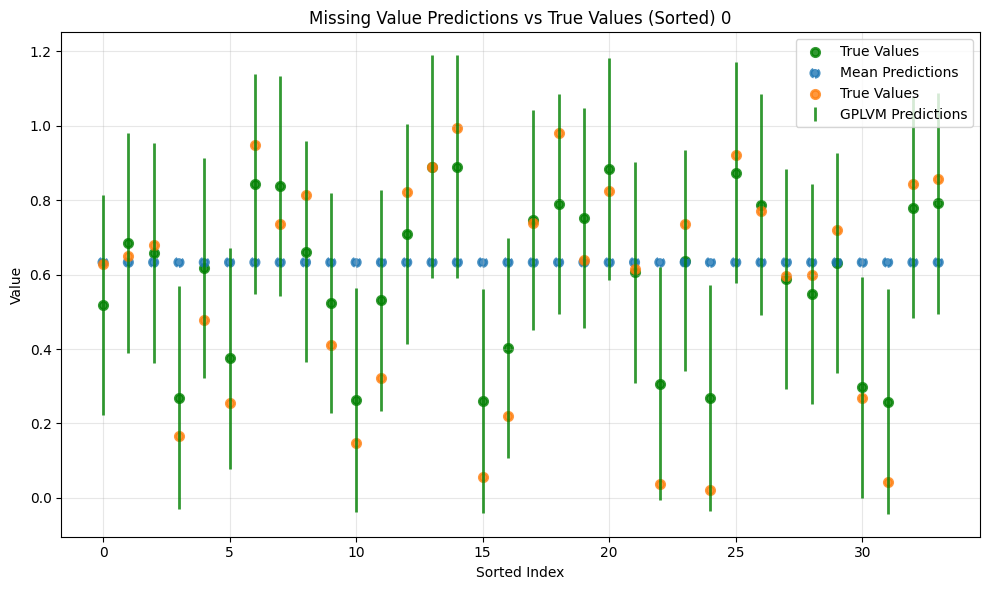

34


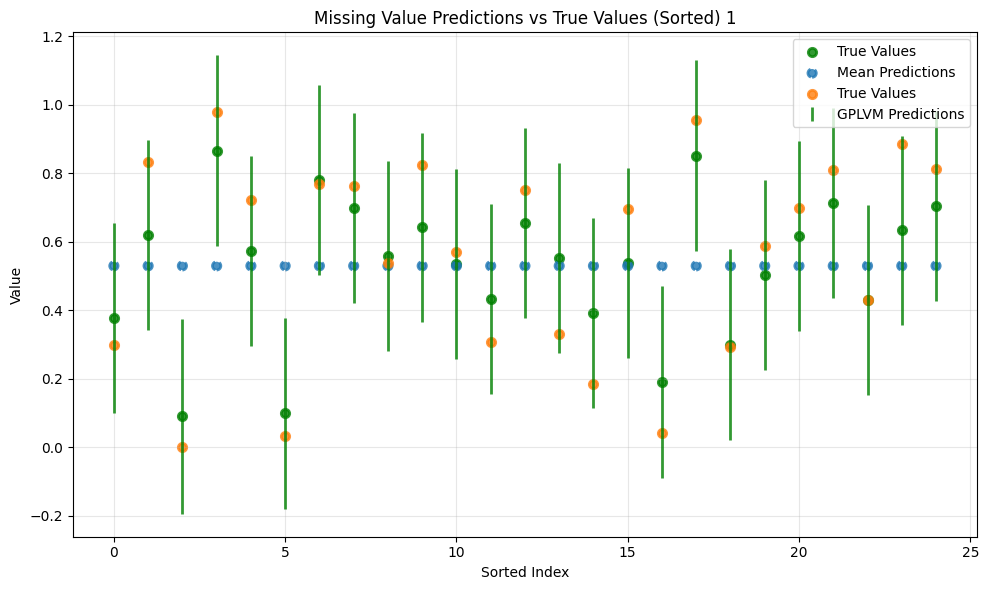

25


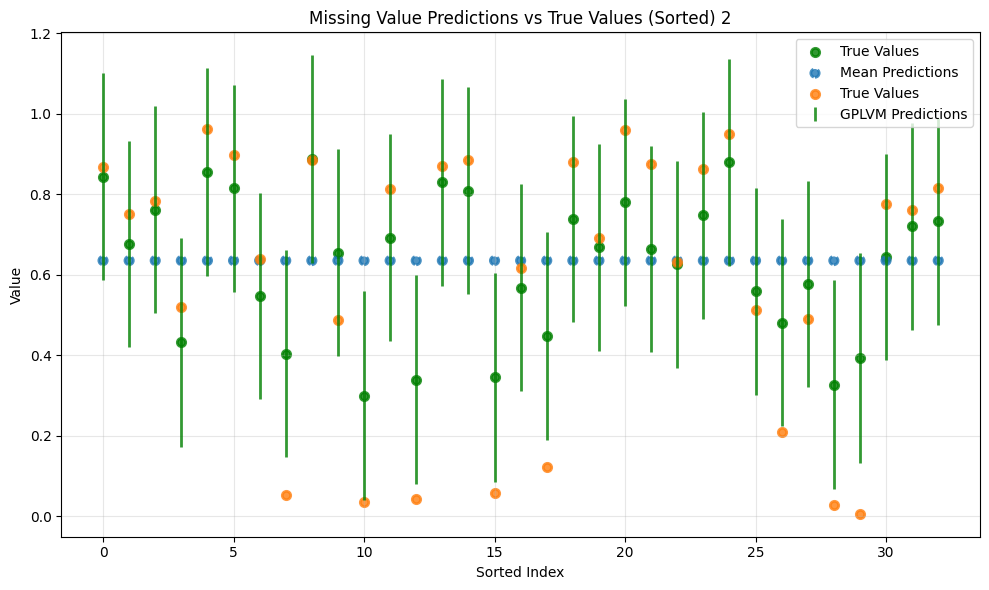

33


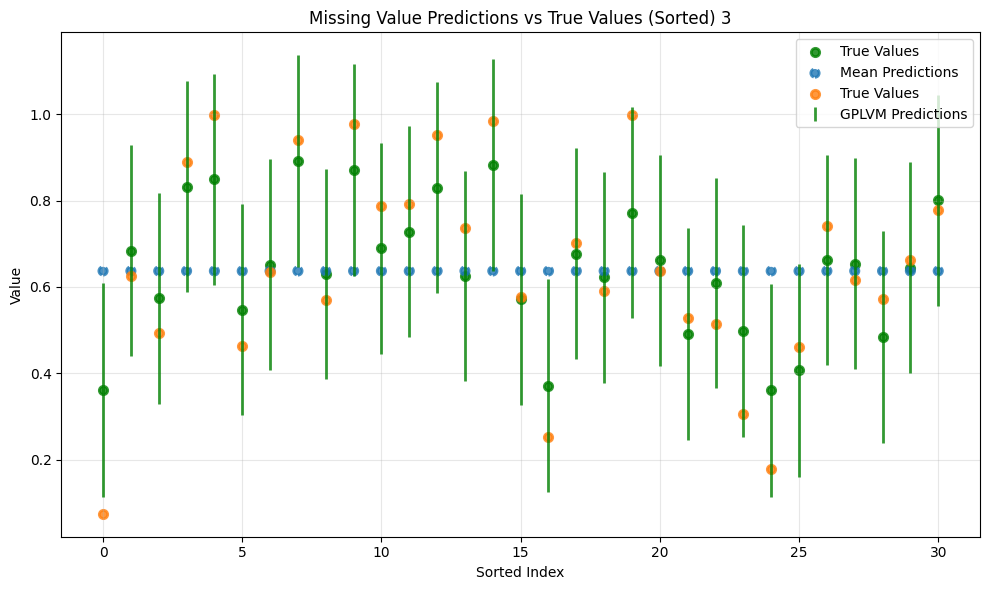

31


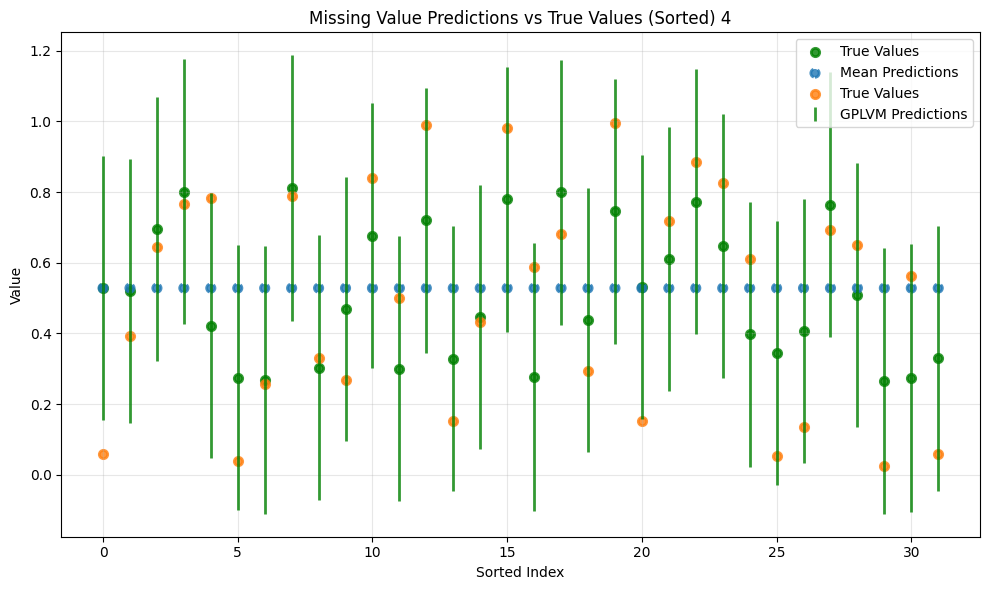

32


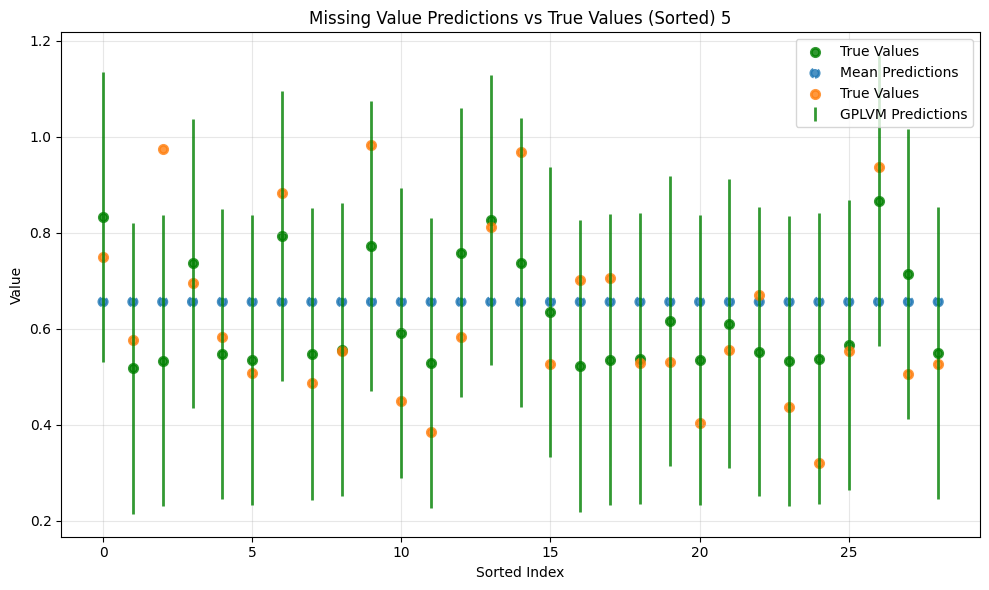

29


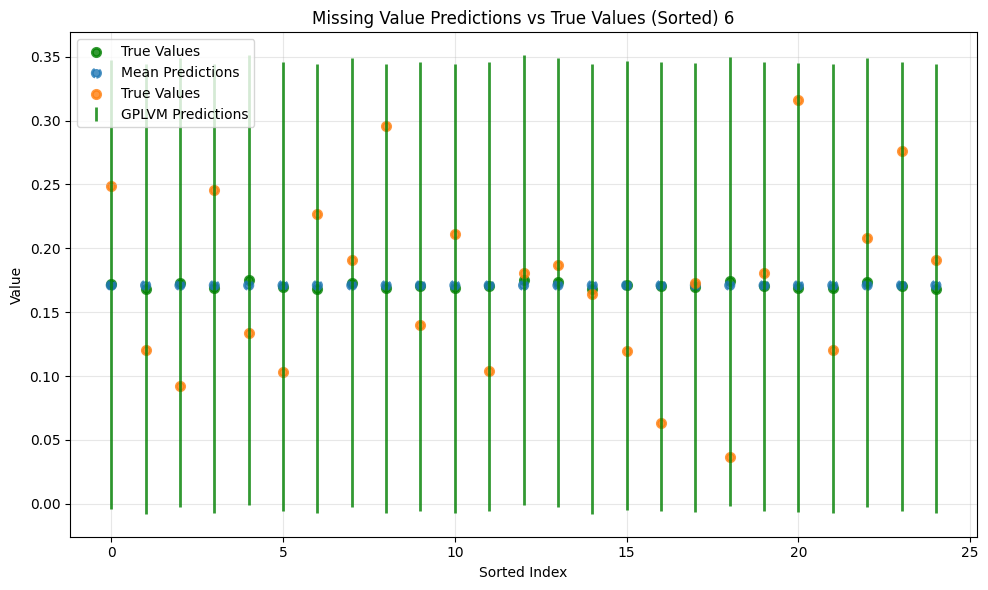

25


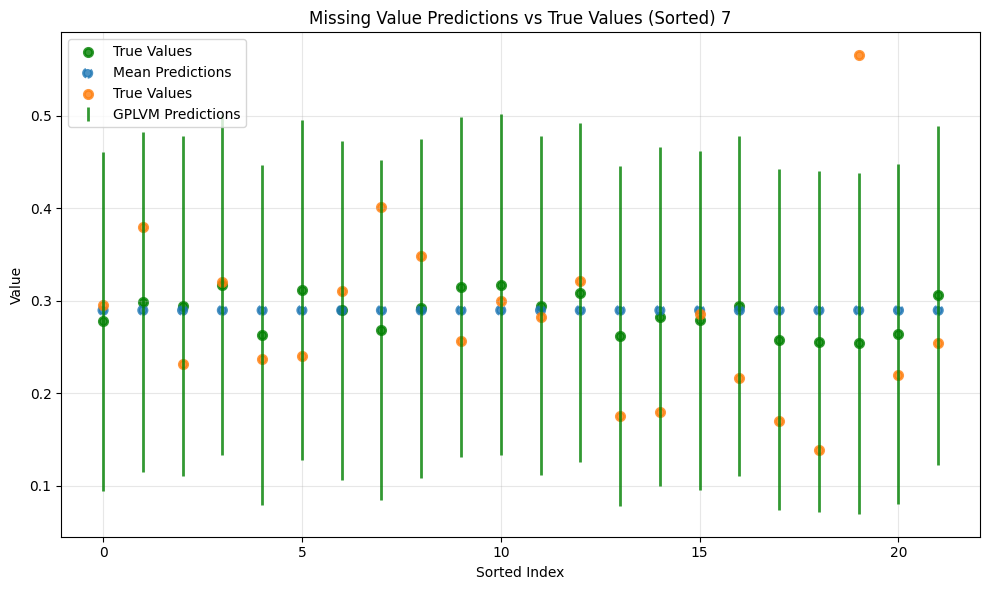

22


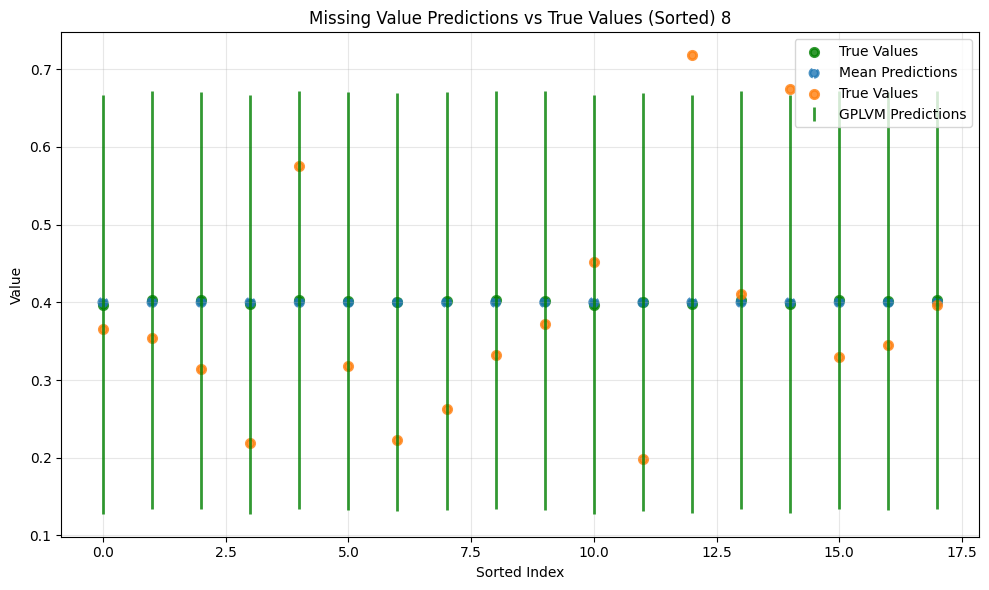

18


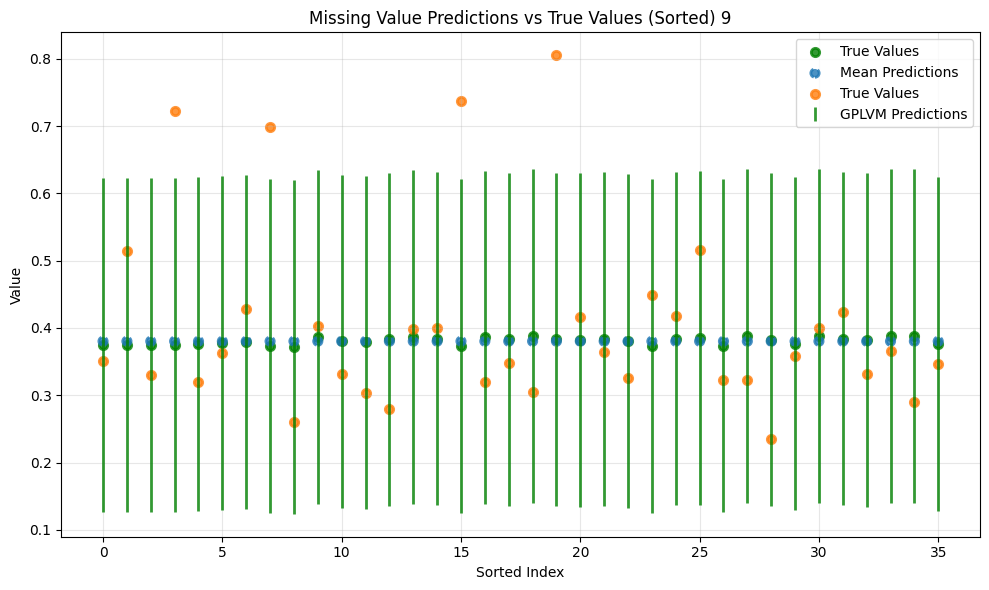

36


In [21]:
import matplotlib.pyplot as plt

for i in range(data_dim):
    
    # Get predictions for missing values
    pred_missing = pred_means[:, i][missing_mask_tensor[:, i]].detach().cpu().numpy()
    pred_std_missing = torch.sqrt(pred_vars[:, i][missing_mask_tensor[:, i]]).detach().cpu().numpy()
    true_missing = data_np[:, i][missing_mask[:, i]]
    mean_pred_missing = mean_predictions[:, i][missing_mask_tensor[:, i]].detach().cpu().numpy()
    std_pred_missing = std_predictions[:, i][missing_mask_tensor[:, i]].detach().cpu().numpy()

    # Sort by true values
    sort_idx = np.argsort(true_missing)
    true_sorted = true_missing[sort_idx]
    pred_sorted = pred_missing[sort_idx]
    pred_std_sorted = pred_std_missing[sort_idx]
    mean_sorted = mean_pred_missing[sort_idx]
    std_sorted = std_pred_missing[sort_idx]

    # Plot
    plt.figure(figsize=(10, 6))
    plt.scatter(sort_idx, pred_sorted, label='True Values', linewidth=2, alpha=0.8, c='g')
    plt.errorbar(sort_idx, pred_sorted, yerr=2*pred_std_sorted, c='g', label='GPLVM Predictions', linewidth=2, alpha=0.8, capsize=0, linestyle='None')
    plt.scatter(sort_idx,mean_sorted, label='Mean Predictions', linewidth=2, alpha=0.8, linestyle='--')
    plt.scatter(sort_idx, true_sorted, label='True Values', linewidth=2, alpha=0.8)

    plt.xlabel('Sorted Index')
    plt.ylabel('Value')
    plt.title(f'Missing Value Predictions vs True Values (Sorted) {i}')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    print(len(pred_sorted))

In [22]:
for name, param in model.named_parameters():
    print(name, param.size())

variational_strategy.inducing_points torch.Size([10, 20, 5])
variational_strategy._variational_distribution.variational_mean torch.Size([10, 20])
variational_strategy._variational_distribution.chol_variational_covar torch.Size([10, 20, 20])
X.q_mu torch.Size([195, 5])
X.q_log_sigma torch.Size([195, 5])
covar_module.raw_outputscale torch.Size([10])
covar_module.base_kernel.raw_lengthscale torch.Size([1, 5])


In [23]:
range(data_dim)

range(0, 10)

/var/folders/kx/7zm2zp_54d14zbwnnl84lxlc0000gp/T/ipykernel_62198/3668513496.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')


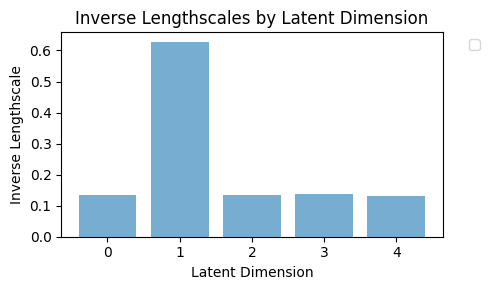

In [24]:
# plot the inverse lengthscales
import matplotlib.pyplot as plt

lengthscales = model.covar_module.base_kernel.lengthscale.detach().cpu().numpy()
inverse_lengthscales = 1.0 / lengthscales

plt.figure(figsize=(5, 3))

plt.bar(range(latent_dim), inverse_lengthscales[0], alpha=0.6)

plt.xlabel('Latent Dimension')
plt.ylabel('Inverse Lengthscale')
plt.title('Inverse Lengthscales by Latent Dimension')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [25]:

import matplotlib.pyplot as plt




# Optionally add labels for each point

In [26]:
for name, param in model.named_parameters():
    print(name, param.size())

variational_strategy.inducing_points torch.Size([10, 20, 5])
variational_strategy._variational_distribution.variational_mean torch.Size([10, 20])
variational_strategy._variational_distribution.chol_variational_covar torch.Size([10, 20, 20])
X.q_mu torch.Size([195, 5])
X.q_log_sigma torch.Size([195, 5])
covar_module.raw_outputscale torch.Size([10])
covar_module.base_kernel.raw_lengthscale torch.Size([1, 5])


In [27]:
print(f"pred_means shape: {pred_means.shape}")
print(f"pred_vars shape: {pred_vars.shape}")
print(f"data_std shape: {data_std.shape}")

pred_means shape: torch.Size([195, 10])
pred_vars shape: torch.Size([195, 10])
data_std shape: torch.Size([10])
